# Notebook n°4: Machine Learning non supervisé

## Objectif

Regrouper les liaisons TGV selon leur durée et les causes historiques de retard, puis étudier si ces groupes présentent des différences de régularité.

## 1. Objectifs de ce notebook

Après avoir étudié la qualité des données dans le notebook 01 et réalisé l'analyse exploratoire dans le notebook 02, nous allons maintenant chercher à regrouper les liaisons TGV selon leurs caractéristiques, sans utiliser les catégories définies précédemment.

Notre objectif est de trouver des groupes de liaisons qui se ressemblent selon leur durée moyenne et les causes de retard, puis de voir si ces groupes sont différents de notre classification géographique (radiales, transversales et internationales).

Nous allons également comparer les taux de retard de ces groupes, sachant que le taux n'a pas été utilisé pour les créer. Cela pourrait nous permettre d'identifier des profils de liaisons associés à des niveaux de retard différents, qui pourraient ensuite être utiles pour la prédiction dans le notebook 05.

## 2. Méthode

Pour cela, nous allons d'abord regrouper les données mensuelles afin d'obtenir un profil pour chaque liaison. Ensuite, nous allons standardiser les variables pour les mettre à la même échelle.

Nous utiliserons la méthode du coude pour choisir le nombre de clusters, puis l'algorithme K-Means pour former les groupes et analyser leurs caractéristiques.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import sys



In [2]:
SEED = 42

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

# Permettre l'import des fonctions de notre projet.
sys.path.insert(0, str(project_root / "src"))

from projet_kit_data.ml.baseline import (
    build_baseline_dataset,
    chronological_split,
    prepare_baseline_data,
)

DATA_PATH = project_root / "data" / "processed" / "sncf.parquet"
data_etl = pd.read_parquet(DATA_PATH)

# Reprendre exactement la séparation chronologique du notebook 03.
data_ml = prepare_baseline_data(data_etl)
dataset_ml = build_baseline_dataset(data_ml, window_months=12)
train_ml, validation_ml, test_ml = chronological_split(
    dataset_ml, train_fraction=0.70, validation_fraction=0.15
)

# Le clustering est construit avec les données disponibles au plus tard
# au dernier mois d'entraînement, sans consulter validation et test.
fin_entrainement = train_ml["date"].max()

data = data_etl.copy()
data["date"] = pd.to_datetime(data["date"])
data = data.loc[data["date"] <= fin_entrainement].copy()

# Exclure les lignes signalées par les contrôles qualité, si présents.
colonnes_flags = [c for c in data.columns if c.startswith("flag_")]
if colonnes_flags:
    a_un_flag = data[colonnes_flags].fillna(False).any(axis=1)
    data = data.loc[~a_un_flag].drop(columns=colonnes_flags).copy()

print("Fin de l'entraînement :", fin_entrainement.date())
print("Validation :", validation_ml["date"].min().date(), "→", validation_ml["date"].max().date())
print("Test :", test_ml["date"].min().date(), "→", test_ml["date"].max().date())
print("Observations historiques pour le clustering :", len(data))
assert data["date"].max() <= fin_entrainement

Fin de l'entraînement : 2024-05-01
Validation : 2024-06-01 → 2025-06-01
Test : 2025-07-01 → 2026-09-01
Observations historiques pour le clustering : 9414


Les profils sont calculés uniquement avec les observations antérieures ou égales à la fin de l'entraînement du notebook 03.

Ce choix permet d'utiliser les clusters comme variables explicatives dans le notebook 05 **sans exploiter les données des mois à prédire**. Il est normal que les effectifs et les résultats soient différents de ceux de la première version du notebook.

In [3]:

# On regroupe les deux sens d'une liaison dans une même paire de gares
data["paire"] = data.apply(
    lambda r: tuple(sorted([r["gare_depart"], r["gare_arrivee"]])),
    axis=1
)

# On définit les gares parisiennes pour classer les liaisons
paris_gares = ["PARIS LYON", "PARIS MONTPARNASSE", "PARIS NORD", "PARIS EST",
               "PARIS VAUGIRARD"]

# On classe les observations selon leur type de liaison
def type_liaison(ligne):
    if ligne["service"] == "International":
        return "international"
    if ligne["gare_depart"] in paris_gares:
        return "radiale depuis Paris"
    if ligne["gare_arrivee"] in paris_gares:
        return "radiale vers Paris"
    return "transversale"

data["type_liaison"] = data.apply(type_liaison, axis=1)

# On affiche le nombre de paires et la répartition des observations par type
print(f"Nombre de paires uniques : {data['paire'].nunique()}")
print("\nRépartition des types de liaisons :")
print(data["type_liaison"].value_counts())


Nombre de paires uniques : 65

Répartition des types de liaisons :
type_liaison
radiale vers Paris      3411
radiale depuis Paris    3409
transversale            1451
international           1143
Name: count, dtype: int64


Nous rassemblons les deux sens d'une même liaison dans une paire de gares. Le type géographique est conservé uniquement pour décrire les groupes obtenus : il ne sert pas à entraîner KMeans.

Ce regroupement simplifie l'analyse, mais il peut masquer des différences entre l'aller et le retour. Dans le notebook 03, le sens de circulation reste pris en compte dans les variables explicatives.

In [4]:
# Construire un profil historique pour chaque paire de gares.
# Les causes de retard observées dans la période d'entraînement sont autorisées :
# elles ne proviennent pas des mois de validation ou de test.
colonnes_causes = [c for c in data.columns if c.startswith("prct_cause")]
features = ["duree_moyenne", *colonnes_causes]

profils = (
    data.groupby("paire", observed=True)[features]
    .mean()
    .dropna()
    .copy()
)

print("Nombre de paires avec un profil complet :", len(profils))
print("Caractéristiques utilisées :", features)
display(profils.head())

Nombre de paires avec un profil complet : 65
Caractéristiques utilisées : ['duree_moyenne', 'prct_cause_externe', 'prct_cause_infra', 'prct_cause_gestion_trafic', 'prct_cause_materiel_roulant', 'prct_cause_gestion_gare', 'prct_cause_prise_en_charge_voyageurs']


,duree_moyenne,prct_cause_externe,prct_cause_infra,prct_cause_gestion_trafic,prct_cause_materiel_roulant,prct_cause_gestion_gare,prct_cause_prise_en_charge_voyageurs
paire,,,,,,,
"(AIX EN PROVENCE TGV, PARIS LYON)",185.620915,26.872116,20.341057,15.050786,22.447296,7.491646,7.797099
"(ANGERS SAINT LAUD, PARIS MONTPARNASSE)",94.292208,23.708313,26.446534,18.877902,15.901985,6.123328,8.941938
"(ANGOULEME, PARIS MONTPARNASSE)",127.688312,20.295296,26.040013,16.700312,17.275062,8.332052,11.357265
"(ANNECY, PARIS LYON)",225.657895,24.331655,22.666283,25.482446,18.937948,4.577241,2.030743
"(ARRAS, PARIS NORD)",50.240260,16.621251,23.199690,26.318829,16.617788,10.519254,6.723189


Chaque ligne représente une paire de gares, décrite par la durée moyenne et les proportions historiques des différentes causes de retard.

**Attention :** ces causes ne seraient pas disponibles pour une prédiction du mois courant. Nous utilisons donc exclusivement leurs moyennes sur la période d'entraînement, qui est déjà connue au moment de prévoir la suite.

### Standardisation

Les durées et les proportions n'ont pas la même échelle. Nous utilisons le score standardisé :

$$z = \frac{x - \mu}{\sigma}$$

Le `StandardScaler` est ajusté uniquement sur les profils historiques d'entraînement.

In [5]:
# Ajuster la normalisation uniquement sur les profils de l'entraînement.
scaler = StandardScaler()
X = scaler.fit_transform(profils[features])

X_scale = pd.DataFrame(X, index=profils.index, columns=features)
print("Après normalisation :")
display(X_scale.describe().round(2).loc[["mean", "std", "min", "max"]])

Après normalisation :

,duree_moyenne,prct_cause_externe,prct_cause_infra,prct_cause_gestion_trafic,prct_cause_materiel_roulant,prct_cause_gestion_gare,prct_cause_prise_en_charge_voyageurs
mean,-0.00,-0.00,0.00,0.00,0.00,-0.00,-0.00
std,1.01,1.01,1.01,1.01,1.01,1.01,1.01
min,-1.50,-2.00,-2.70,-2.12,-3.05,-2.10,-2.14
max,3.00,2.33,2.12,3.71,3.96,2.19,1.85


Nous allons utiliser la méthode du coude, qui nous permettra de choisir le $k$ optimal, donc le nombre de groupes que l’algorithme doit créer. Cette méthode consiste à tester plusieurs valeurs de $k$ et à mesurer, pour chacune, la dispersion totale des points autour de leurs centres de cluster. Cette dispersion est appelée inertie :

$$
I = \sum_{k=1}^{K} \sum_{x \in C_k} \| x - \mu_k \|^2
$$

où $K$ est le nombre de clusters, $C_k$ l'ensemble des liaisons appartenant au cluster $k$, et $\mu_k$ le centre de ce cluster. Plus $k$ augmente, plus l'inertie diminue. Le "coude" de la courbe indique la valeur de $k$ où ajouter un cluster supplémentaire n'apporte plus beaucoup de gain.

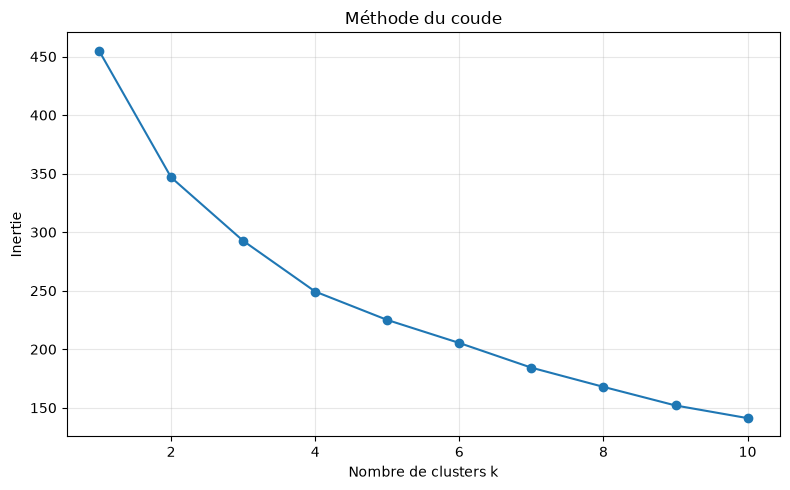

In [6]:
# Chercher un nombre de clusters raisonnable sur les profils d'entraînement.
valeurs_k = range(1, min(10, len(profils)) + 1)
inerties = []
for k in valeurs_k:
    kmeans_test = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    kmeans_test.fit(X)
    inerties.append(kmeans_test.inertia_)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(list(valeurs_k), inerties, marker="o")
ax.set_xlabel("Nombre de clusters k")
ax.set_ylabel("Inertie")
ax.set_title("Méthode du coude")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La méthode du coude montre comment l'inertie diminue lorsque le nombre de clusters augmente.

Nous conservons **quatre clusters** pour avoir des groupes assez détaillés tout en gardant une interprétation simple et une comparaison possible avec la typologie géographique.

Ce choix reste exploratoire : quatre clusters ne correspondent pas forcément au nombre optimal. Les tailles et les profils des groupes sont calculés uniquement sur la période d'entraînement.

In [7]:
# Ajuster KMeans uniquement sur les données d'entraînement.
kmeans = KMeans(n_clusters=4, random_state=SEED, n_init=10)
profils["cluster"] = kmeans.fit_predict(X)

print("Répartition des paires par cluster :")
print(profils["cluster"].value_counts().sort_index())

Répartition des paires par cluster :
cluster
0     4
1    18
2    24
3    19
Name: count, dtype: int64


Les clusters regroupent les paires de gares selon leurs caractéristiques historiques, sans utiliser le taux de retard comme variable de clustering.

Les numéros `0`, `1`, `2` et `3` sont arbitraires : leur signification dépend des données et peut changer après ce recalcul.

### Régularité observée dans la période d'entraînement

Nous décrivons chaque groupe par son taux de retard de plus de 15 minutes. Pour rester cohérents avec la cible du notebook 03, le dénominateur est le **nombre de trains ayant circulé** et non le nombre de trains prévus :

$$\text{Taux retard > 15 min} = \frac{\sum \text{trains retardés > 15 min}}{\sum (\text{trains prévus} - \text{annulations})} \times 100$$

Ce taux sert ici à décrire les groupes. Il ne sert pas à entraîner KMeans et n'est pas calculé avec les résultats de validation ou de test.

In [8]:
# Calculer le taux de retard sur les observations historiques valides.
profil_clusters = profils.groupby("cluster")[features].mean().round(2)

train_historique = data_ml.loc[
    (pd.to_datetime(data_ml["date"]) <= fin_entrainement)
    & data_ml["valid_target"]
].copy()

# Faire correspondre les paires de gares aux mêmes groupes.
train_historique["paire"] = train_historique.apply(
    lambda r: tuple(sorted((r["departure"], r["arrival"]))), axis=1
)
train_historique["cluster"] = train_historique["paire"].map(
    profils["cluster"].to_dict()
)
train_historique = train_historique.dropna(subset=["cluster"])

# Pondérer le taux par le nombre de trains réellement en circulation.
volumes = train_historique.groupby("cluster")[["late_15", "circulated"]].sum()
taux_par_cluster = (100 * volumes["late_15"] / volumes["circulated"]).round(2)

profil_clusters["taux_retard_15_pct"] = taux_par_cluster
profil_clusters["nombre_paires"] = profils["cluster"].value_counts().sort_index()
profil_clusters["nombre_trains"] = volumes["circulated"]
display(profil_clusters)

,duree_moyenne,prct_cause_externe,prct_cause_infra,prct_cause_gestion_trafic,prct_cause_materiel_roulant,prct_cause_gestion_gare,prct_cause_prise_en_charge_voyageurs,taux_retard_15_pct,nombre_paires,nombre_trains
cluster,,,,,,,,,,
0,285.26,17.42,12.98,29.83,15.41,4.26,3.43,17.73,4,51132
1,169.54,22.38,22.87,20.59,21.51,6.13,3.99,11.05,18,444966
2,112.77,19.11,20.99,21.90,19.13,9.18,9.09,8.50,24,1154920
3,226.16,27.23,24.23,15.17,18.00,5.40,8.55,11.18,19,761258


Le tableau permet de décrire chaque cluster à partir de sa durée moyenne, des causes de retard historiques et de son taux de retard observé **pendant l'entraînement**.

Il faut interpréter les résultats affichés après exécution : les valeurs et les numéros des clusters ne sont plus nécessairement ceux de la première version, qui utilisait toute la période.

In [9]:
# Afficher les paires du cluster présentant le taux de retard le plus élevé.
cluster_plus_retarde = int(profil_clusters["taux_retard_15_pct"].idxmax())
print(f"Cluster au taux de retard le plus élevé : {cluster_plus_retarde}")
print("=" * 60)
for paire in profils.index[profils["cluster"] == cluster_plus_retarde]:
    print(f"  {paire[0]} - {paire[1]}")

print("\nExemples des autres clusters :")
for numero in sorted(profils["cluster"].unique()):
    if numero == cluster_plus_retarde:
        continue
    liaisons = profils.index[profils["cluster"] == numero].tolist()
    print(f"\nCluster {numero} ({len(liaisons)} paires) :")
    for paire in liaisons[:5]:
        print(f"  {paire[0]} - {paire[1]}")

Cluster au taux de retard le plus élevé : 0
  FRANCFORT - PARIS EST
  ITALIE - PARIS LYON
  MADRID - MARSEILLE ST CHARLES
  PARIS EST - STUTTGART

Exemples des autres clusters :

Cluster 1 (18 paires) :
  ANNECY - PARIS LYON
  BELLEGARDE (AIN) - PARIS LYON
  BESANCON FRANCHE COMTE TGV - PARIS LYON
  BORDEAUX ST JEAN - PARIS VAUGIRARD
  BORDEAUX ST JEAN - TOURCOING

Cluster 2 (24 paires) :
  ANGOULEME - PARIS MONTPARNASSE
  ARRAS - PARIS NORD
  AVIGNON TGV - PARIS LYON
  DOUAI - PARIS NORD
  LAVAL - PARIS MONTPARNASSE

Cluster 3 (19 paires) :
  AIX EN PROVENCE TGV - PARIS LYON
  ANGERS SAINT LAUD - PARIS MONTPARNASSE
  BARCELONA - PARIS LYON
  BORDEAUX ST JEAN - PARIS MONTPARNASSE
  BREST - PARIS MONTPARNASSE


Les exemples permettent de vérifier si les paires d'un même cluster ont des caractéristiques communes. On ne suppose pas à l'avance qu'un numéro précis correspond aux liaisons longues ou internationales : cette interprétation dépend des résultats de la nouvelle exécution.

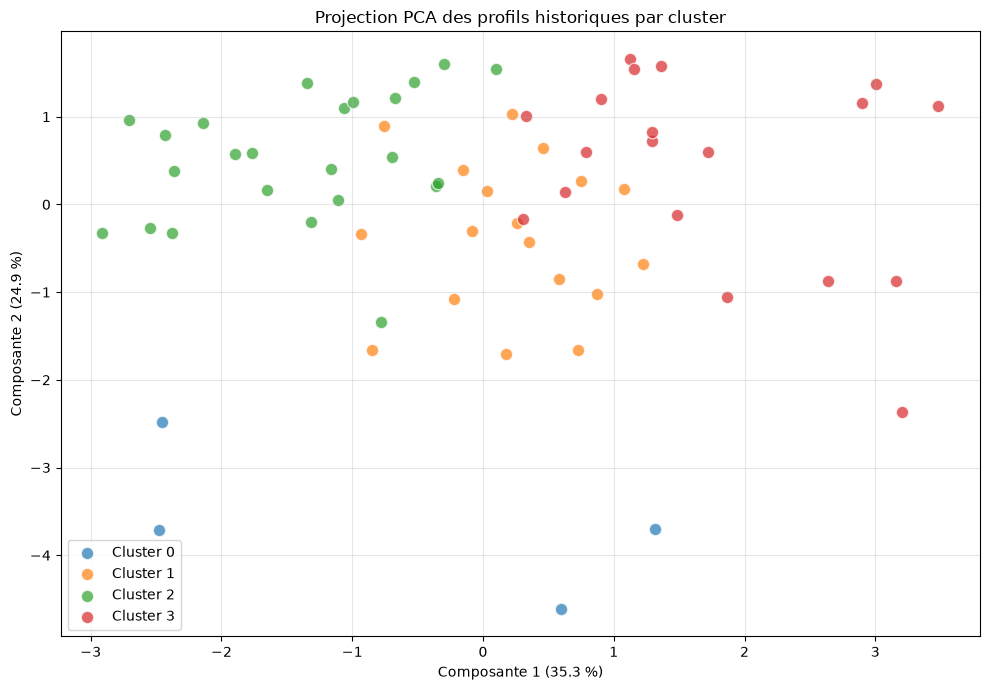

Variance expliquée : 60.3 %


In [10]:
# Réduire les caractéristiques en deux dimensions pour visualiser les clusters.
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(10, 7))
for numero in sorted(profils["cluster"].unique()):
    masque = profils["cluster"] == numero
    ax.scatter(
        coords[masque, 0], coords[masque, 1],
        label=f"Cluster {numero}", s=80, alpha=0.7,
        edgecolors="white",
    )

ax.set_xlabel(f"Composante 1 ({pca.explained_variance_ratio_[0] * 100:.1f} %)")
ax.set_ylabel(f"Composante 2 ({pca.explained_variance_ratio_[1] * 100:.1f} %)")
ax.set_title("Projection PCA des profils historiques par cluster")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"Variance expliquée : {pca.explained_variance_ratio_.sum() * 100:.1f} %")

Cette projection résume les caractéristiques historiques des paires de gares en deux axes. Elle aide à visualiser les groupes, mais n'intervient pas dans la construction des clusters utilisés pour la prédiction.

In [11]:
# Comparer les clusters avec une typologie adaptée aux paires non orientées.
# Une paire internationale reste internationale ; sinon, la présence
# d'une gare parisienne suffit à la classer comme radiale.
paires_internationales = set(
    data.loc[data["service"] == "International", "paire"]
)


def type_paire(paire):
    if paire in paires_internationales:
        return "international"
    if any(gare in paris_gares for gare in paire):
        return "radiale"
    return "transversale"


# On évite de choisir arbitrairement le type de la première observation.
profils["type_liaison"] = [type_paire(paire) for paire in profils.index]

tableau_croise = pd.crosstab(
    profils["type_liaison"],
    profils["cluster"],
    margins=True,
    margins_name="Total",
)
print("Répartition des paires par type et par cluster :")
display(tableau_croise)

Répartition des paires par type et par cluster :


cluster,0,1,2,3,Total
type_liaison,,,,,
international,4,3,0,1,8
radiale,0,14,18,15,47
transversale,0,1,6,3,10
Total,4,18,24,19,65


In [12]:
# Exporter la correspondance pour le notebook 05.
# Ce fichier ne contient que les clusters appris sur l'entraînement.
chemin_sortie = project_root / "data" / "processed" / "clusters_liaisons.csv"

export_clusters = profils[["cluster"]].reset_index()

# Vérifier qu'il n'y a qu'une ligne et un cluster par paire.
assert export_clusters["paire"].is_unique
assert export_clusters["cluster"].notna().all()

export_clusters.to_csv(chemin_sortie, index=False)

print("Clusters sauvegardés dans :", chemin_sortie)
print("Nombre de paires exportées :", len(export_clusters))
print("Dernier mois autorisé pour apprendre les clusters :", fin_entrainement.date())
display(export_clusters.head())

Clusters sauvegardés dans : c:\Users\mariu\IADATA701-PROJET\data\processed\clusters_liaisons.csv
Nombre de paires exportées : 65
Dernier mois autorisé pour apprendre les clusters : 2024-05-01


,paire,cluster
0,"(AIX EN PROVENCE TGV, PARIS LYON)",3
1,"(ANGERS SAINT LAUD, PARIS MONTPARNASSE)",3
2,"(ANGOULEME, PARIS MONTPARNASSE)",2
3,"(ANNECY, PARIS LYON)",1
4,"(ARRAS, PARIS NORD)",2



### Export

Nous enregistrons les résultats de K-Means afin de pouvoir les réutiliser dans le notebook 05 et dans l'application Streamlit.

Nous conservons les clusters attribués aux liaisons, les profils utilisés pour les construire, ainsi que le modèle K-Means et la normalisation.

Les clusters ont été appris uniquement sur les données d'entraînement. Ils pourront donc être réutilisés sans consulter les mois de validation ou de test.


In [13]:

import joblib

# Créer les dossiers pour les résultats et les modèles.
dossier_resultats = project_root / "data" / "processed" / "ml"
dossier_modeles = project_root / "models"

dossier_resultats.mkdir(parents=True, exist_ok=True)
dossier_modeles.mkdir(parents=True, exist_ok=True)

# Enregistrer les profils historiques et leur cluster.
# Ils serviront notamment à explorer les liaisons dans Streamlit.
profils_export = profils.reset_index().copy()

# Séparer les gares pour faciliter la lecture et les jointures.
profils_export["gare_1"] = profils_export["paire"].str[0]
profils_export["gare_2"] = profils_export["paire"].str[1]

profils_export = profils_export.drop(columns="paire")

profils_export.to_parquet(
    dossier_resultats / "clusters_profils.parquet",
    index=False,
)

# Conserver le résumé des caractéristiques de chaque cluster.
profil_clusters.reset_index().to_parquet(
    dossier_resultats / "clusters_resume.parquet",
    index=False,
)

# Sauvegarder la normalisation et K-Means ensemble.
# On conserve aussi les variables et la période d'apprentissage.
clustering_export = {
    "scaler": scaler,
    "kmeans": kmeans,
    "features": features,
    "fin_entrainement": fin_entrainement,
}

joblib.dump(
    clustering_export,
    dossier_modeles / "clustering_model.joblib",
)

# Vérifier les exports.
print("Export du clustering terminé.")
print("Nombre de paires :", len(profils_export))
print("Nombre de clusters :", kmeans.n_clusters)
print("Dossier des résultats :", dossier_resultats)
print("Modèle :", dossier_modeles / "clustering_model.joblib")


Export du clustering terminé.
Nombre de paires : 65
Nombre de clusters : 4
Dossier des résultats : c:\Users\mariu\IADATA701-PROJET\data\processed\ml
Modèle : c:\Users\mariu\IADATA701-PROJET\models\clustering_model.joblib


## Bilan et utilisation dans le notebook 05

Nous avons regroupé les paires de gares selon leur durée et les causes de retard **observées avant la fin de l'entraînement**. Les groupes ont été construits sans utiliser les données de validation ni de test.

La comparaison avec les types géographiques et les taux de retard de l'entraînement permet d'interpréter les profils. Les numéros de cluster ne représentent pas un classement de gravité.

Le fichier `data/processed/clusters_liaisons.csv` contient la correspondance entre chaque paire connue à l'entraînement et son cluster. Il peut maintenant être chargé dans le notebook 05.

**Limites à respecter dans le notebook 05 :**

- Une paire apparue uniquement après la période d'entraînement peut ne pas avoir de cluster : il ne faut pas la supprimer silencieusement sans vérifier l'effet sur le jeu évalué.
- Les clusters sont issus de données historiques : pour une prévision mensuelle, ne jamais les recalculer avec des retards ou causes de retard du mois à prédire.
- Le notebook 05 devra conserver le même découpage chronologique que le notebook 03 et comparer les modèles sur les mêmes observations.

On pourra ainsi étudier l'intérêt prédictif des clusters sans introduire de fuite temporelle dans leur construction.